# V1DD soma-feature UMAP embedding

Compute a 2D UMAP from `v1dd_soma_features`, restricted to cells with an r84 cell-type sub-class, and store it with the release-ingest embedding schema.

In [ ]:
import json

import numpy as np
import polars as pl
import umap
from sklearn.preprocessing import StandardScaler

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import (
    read_embedding_locations,
    write_models,
)
from connects_common_connectivity.models import (
    EmbeddingLocation,
    EmbeddingMethod,
    EmbeddingSpace,
)

In [ ]:
OUTPUT_ROOT = get_settings().output_root
PROJECT_ID = "v1dd"
DENDRITE_DATASET_ID = "v1dd_1196_em"
SOURCE_FEATURE_SET_ID = "v1dd_soma_features"
EMBEDDING_SPACE_ID = "v1dd_soma_feature_umap"
RANDOM_STATE = 42

## Read the soma feature matrix

In [5]:
source_feature_set = (
    pl.read_delta(OUTPUT_ROOT / "cellfeatureset")
    .filter((pl.col("project_id") == PROJECT_ID) & (pl.col("id") == SOURCE_FEATURE_SET_ID))
)
assert source_feature_set.height == 1, f"Expected one CellFeatureSet named {SOURCE_FEATURE_SET_ID}."

SOURCE_FEATURE_COLUMNS = source_feature_set["feature_definition_ids"].to_list()[0]

soma_features = (
    pl.read_delta(OUTPUT_ROOT / f"cellfeatures/{SOURCE_FEATURE_SET_ID}")
    .filter(pl.col("project_id") == PROJECT_ID)
)
print(soma_features.shape)
print(SOURCE_FEATURE_COLUMNS)

(121429, 14)
['nucleus_volume_um', 'nucleus_area_um', 'nuclear_area_to_volume_ratio', 'nuclear_folding_area_um', 'fraction_nuclear_folding', 'nucleus_to_soma_ratio', 'soma_volume_um', 'soma_area_um', 'soma_to_nucleus_center_dist', 'soma_area_to_volume_ratio', 'soma_synapse_density_um']


In [6]:
soma_features.head()

id,project_id,feature_set_id,nucleus_volume_um,nucleus_area_um,nuclear_area_to_volume_ratio,nuclear_folding_area_um,fraction_nuclear_folding,nucleus_to_soma_ratio,soma_volume_um,soma_area_um,soma_to_nucleus_center_dist,soma_area_to_volume_ratio,soma_synapse_density_um
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""864691132064728775""","""v1dd""","""v1dd_soma_features""",75.408874,99.754323,1.155667,0.862728,0.008649,0.994254,75.844669,103.309745,0.115835,1.192268,0.0
"""864691132996695586""","""v1dd""","""v1dd_soma_features""",344.828985,396.716028,1.668245,117.974067,0.297377,0.343134,1004.941085,988.880728,2.038178,2.038134,0.070787
"""864691132714205199""","""v1dd""","""v1dd_soma_features""",427.142249,354.602282,1.292833,14.901609,0.042023,0.374612,1140.226718,1386.82604,0.987635,2.627506,0.062733
"""864691132752649332""","""v1dd""","""v1dd_soma_features""",37.656724,79.492708,1.463125,4.618982,0.058106,0.391498,96.186149,224.2728,1.465404,2.209111,0.111471
"""864691132449910574""","""v1dd""","""v1dd_soma_features""",81.627359,117.91269,1.295744,0.123946,0.001051,0.989435,82.499002,123.486054,0.130915,1.347415,0.0


## Read r84 cell-type labels

Only cells with a `Sub-class` assignment in `v1dd_cell_types_r84` are embedded.

In [ ]:
HIERARCHY_ID = "v1dd_cell_types_r84"
FALLBACK_COLOR = "#c8c8c8"

clusters = (
    pl.read_delta(OUTPUT_ROOT / "cluster")
    .filter(pl.col("hierarchy_id") == HIERARCHY_ID)
)
memberships = (
    pl.read_delta(OUTPUT_ROOT / "clustermembership")
    .filter(
        (pl.col("project_id") == PROJECT_ID)
        & (pl.col("hierarchy_id") == HIERARCHY_ID)
    )
)

subclass_ids = clusters.filter(
    pl.col("hierarchy_category") == "Sub-class"
)["id"].to_list()
cluster_ids = clusters.filter(
    pl.col("hierarchy_category") == "Cluster"
)["id"].to_list()
color_by_cluster = dict(
    zip(clusters["id"].to_list(), clusters["hex_color"].to_list())
)

celltype_ids = set(
    memberships.filter(
        pl.col("cluster").is_in(subclass_ids)
    )["item"].to_list()
)
assert celltype_ids, (
    "No r84 sub-class memberships found; run "
    "etl_v1dd_01_cave_dataset_celltypes.ipynb."
)

print(f"sub-classes: {subclass_ids}")
print(f"source clusters: {len(cluster_ids)}")
print(f"cells with a sub-class: {len(celltype_ids)}")

leaf cell types: ['DTC', 'ITC', 'L2-IT', 'L3-IT', 'L4-IT', 'L5-ET', 'L5-IT', 'L5-NP', 'L6-CT', 'L6-IT', 'PTC', 'STC']
cluster memberships: 147576
cells with a fine cell type: 49192


## Data validation cleanup

In [8]:
assoc = (
    pl.read_delta(OUTPUT_ROOT / "dataitem_dataset_association")
    .filter((pl.col("project_id") == PROJECT_ID) & (pl.col("dataset_id") == DENDRITE_DATASET_ID))
)
assert assoc.shape[0] > 0, f"No DataItems found for {DENDRITE_DATASET_ID}."

dendrite_ids = set(assoc["dataitem_id"].to_list())
labeled_ids = dendrite_ids & celltype_ids
soma_features_cc = (
    soma_features
    .select(["id"] + SOURCE_FEATURE_COLUMNS)
    .with_columns([pl.col(c).cast(pl.Float64) for c in SOURCE_FEATURE_COLUMNS])
    .filter(pl.col("id").is_not_null())
    .filter(pl.all_horizontal([pl.col(c).is_finite() for c in SOURCE_FEATURE_COLUMNS]))
    .filter(pl.col("id").is_in(list(labeled_ids)))
    .unique(subset=["id"], keep="first")
)

assert soma_features_cc.height > 0, "No soma feature rows remained after dataset/cell type filter."
assert set(soma_features_cc["id"].to_list()).issubset(labeled_ids)

print(f"registered rootids: {len(dendrite_ids)}")
print(f"registered rootids with a cell type: {len(labeled_ids)}")
print(f"soma feature rows kept: {soma_features_cc.height} of {soma_features.height}")

registered rootids: 143448
registered rootids with a cell type: 49192
soma feature rows kept: 44150 of 121429


## Compute the UMAP

Features are z-scored before embedding so that the very different scales (volumes in
µm³ vs. dimensionless ratios) contribute comparably to the neighbor graph.

In [9]:
X = soma_features_cc.select(SOURCE_FEATURE_COLUMNS).to_numpy()
X_scaled = StandardScaler().fit_transform(X)
print(X_scaled.shape)

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=RANDOM_STATE,
)
embedding = reducer.fit_transform(X_scaled)
assert embedding.shape == (soma_features_cc.height, 2)
assert np.isfinite(embedding).all()
print(embedding.shape)

(44150, 11)


/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(44150, 2)


In [ ]:
embedding_frame = soma_features_cc.select(
    pl.col("id").alias("dataitem_id")
).with_columns(
    pl.Series("x", embedding[:, 0].astype("float64")),
    pl.Series("y", embedding[:, 1].astype("float64")),
)
embedding_frame.head()

id,umap_x,umap_y
str,f64,f64
"""864691132818917119""",9.628118,-0.81624
"""864691132900532100""",-1.118166,3.670881
"""864691132925277737""",-1.771256,4.283275
"""864691132743408318""",13.712808,5.365205
"""864691132735946923""",7.811237,8.475665


## Write the embedding

In [ ]:
embedding_space = EmbeddingSpace(
    id=EMBEDDING_SPACE_ID,
    name="V1DD soma-feature UMAP",
    description="UMAP of V1DD soma/nucleus morphology features for cells with an r84 sub-class.",
    embedding_method=EmbeddingMethod.UMAP,
    parameters_json=json.dumps(
        {
            "preprocessing": "StandardScaler",
            "n_components": 2,
            "n_neighbors": 15,
            "min_dist": 0.1,
            "metric": "euclidean",
            "random_state": RANDOM_STATE,
        }
    ),
    input_feature_set_id=SOURCE_FEATURE_SET_ID,
    input_features_description=(
        f"All {len(SOURCE_FEATURE_COLUMNS)} features in {SOURCE_FEATURE_SET_ID}, "
        f"restricted to cells with a {HIERARCHY_ID} Sub-class assignment."
    ),
    project_id=PROJECT_ID,
)
result = write_models([embedding_space], output_root=OUTPUT_ROOT)
print(f"EmbeddingSpace rows written: {result.rows_written}")

WrittenResult(class_name='CellFeatureDefinition', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeaturedefinition'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND feature_set_id = 'v1dd_soma_feature_umap'",), rows_written=2)

In [ ]:
embedding_locations = [
    EmbeddingLocation(
        dataitem_id=row["dataitem_id"],
        embedding_space=EMBEDDING_SPACE_ID,
        x=float(row["x"]),
        y=float(row["y"]),
        project_id=PROJECT_ID,
    )
    for row in embedding_frame.iter_rows(named=True)
]
print(f"EmbeddingLocation rows prepared: {len(embedding_locations)}")

WrittenResult(class_name='CellFeatureSet', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeatureset'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND id = 'v1dd_soma_feature_umap'",), rows_written=1)

In [ ]:
result = write_models(embedding_locations, output_root=OUTPUT_ROOT)
print(f"EmbeddingLocation rows written: {result.rows_written}")

WrittenResult(class_name='CellFeatureMatrix', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeaturematrix'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND feature_set_id = 'v1dd_soma_feature_umap'",), rows_written=1)

In [ ]:
stored_embedding = read_embedding_locations(
    PROJECT_ID,
    embedding_space_ids=EMBEDDING_SPACE_ID,
    output_root=OUTPUT_ROOT,
)
assert stored_embedding.height == len(embedding_locations)
print("Stored embedding locations:", stored_embedding.shape)

wrote 2 feature definitions
wrote wide feature matrix rows: 44150


## Plot the embedding by Sub-class and Cluster

Colors come from the r84 hierarchy. Source cluster leaves inherit their mapped sub-class color except for the explicit `L6b` color.

In [15]:
import matplotlib.pyplot as plt

In [ ]:
def embedding_with_clusters(cluster_ids):
    assignments = (
        memberships
        .filter(pl.col("cluster").is_in(cluster_ids))
        .select(
            pl.col("item").alias("dataitem_id"),
            pl.col("cluster"),
        )
        .unique(subset=["dataitem_id"], keep="first")
    )
    return stored_embedding.select(
        "dataitem_id", "x", "y"
).join(assignments, on="dataitem_id", how="inner")

def plot_embedding(frame, title, ax, point_size=2.0):
    order = (
        frame.group_by("cluster")
        .len()
        .sort("len", descending=True)["cluster"]
        .to_list()
    )
    for cluster_id in order:
        group = frame.filter(pl.col("cluster") == cluster_id)
        ax.scatter(
            group["x"].to_numpy(),
            group["y"].to_numpy(),
            s=point_size,
            linewidths=0,
            color=color_by_cluster.get(cluster_id) or FALLBACK_COLOR,
            label=f"{cluster_id} (n={group.height})",
        )
    ax.set_xlabel("embedding x")
    ax.set_ylabel("embedding y")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend(
        markerscale=6,
        fontsize=7,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
    )
    return ax

cells with a fine cell type  : 44150 of 44150
cells with a coarse E/I label: 44150 of 44150


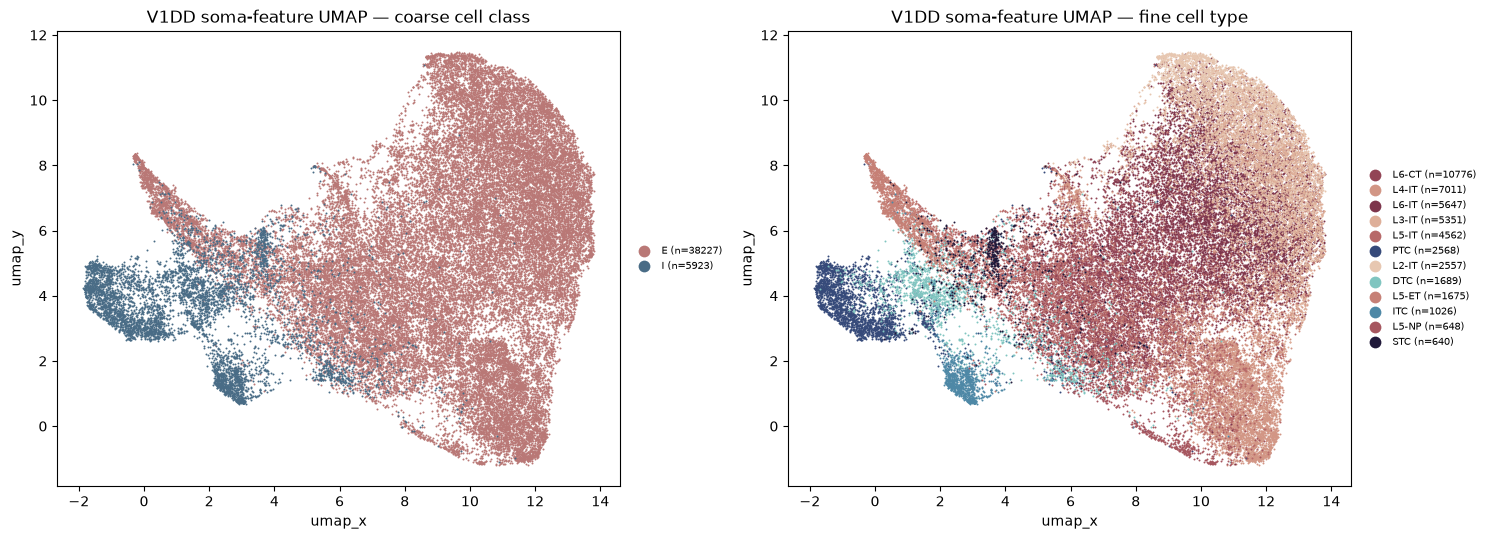

In [ ]:
subclass_df = embedding_with_clusters(subclass_ids)
cluster_df = embedding_with_clusters(cluster_ids)
print(f"cells with a sub-class: {subclass_df.height} of {stored_embedding.height}")
print(f"cells with a source cluster: {cluster_df.height} of {stored_embedding.height}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_embedding(
    subclass_df, "V1DD soma-feature UMAP - Sub-class", axes[0]
)
plot_embedding(
    cluster_df, "V1DD soma-feature UMAP - Cluster", axes[1]
)
fig.tight_layout()
plt.show()